![Banner](../images/09_09_banner_rs_image_classification.png)


# Image Processing

Before any classifier sees a satellite image, the image is cleaned, resampled, stretched, filtered and enriched with edge and texture layers.


## Overview

These steps decide how well the classes separate. This notebook walks through the standalone toolbox `geolattice.rsense.image_processing`, and for every algorithm gives the mathematics, the function that implements it, and a result on real imagery.

The module follows the OpenCV and scikit-image tutorials but needs only `geolattice[rsense]` (NumPy, SciPy, scikit-image). Every function takes an `xarray.DataArray` with dims `(band, y, x)` (CRS and coordinates are kept) or a NumPy array, and ignores NaN pixels.


## Core concepts

### Learning objectives

1. Describe an image as a function $I(x, y, b)$ on a grid and move between arrays, DataArrays and GeoTIFF files.
2. Convert color spaces and explain what each channel measures.
3. Resample and warp an image with the right interpolation and know what happens to the georeferencing.
4. Stretch, gamma-correct, equalize and match histograms.
5. Threshold an image with Otsu's method and clean the mask with morphology.
6. Smooth, denoise and sharpen with convolution, median, bilateral and total-variation filters, and measure the result with PSNR.
7. Detect edges (Sobel, Roberts, Prewitt, Scharr, Laplacian, Canny) and corners (Harris), and describe shape with HOG.
8. Turn processed layers into a feature matrix for a classifier.

### Data

All images are in `Data/08_remote_sensing/08_09_image_classification/Image_processing`:

| File | What it is | Use here |
|---|---|---|
| `crop_field.jpg` | 775 × 610 RGB photo of farm fields | most 2-D demonstrations |
| `sw_030.TIF` | 15965 × 11509 RGB aerial (drone) mosaic, Bangladesh UTM (BUTM 2010), 1.8 cm pixels | a window, block-averaged, to show georeferenced geometry |
| `multi_AOI.tif` | 8-band, 1.6 m multispectral image with no-data gaps | NaN handling, indices, histogram matching |
| `Planet/before/B1-B4.tif` | 3 m Planet bands (blue, green, red, near infrared) | NDVI, thresholding, morphology |

### Contents

1. Setup and data
2. The image model, I/O and image information
3. Color spaces
4. Geometric transformations
5. Radiometric operations
6. Thresholding
7. Filtering and denoising
8. Edge detection
9. Morphology
10. Feature detection and descriptors
11. A multispectral workflow with no-data
12. From processed layers to a classifier
13. Summary, exercises and references


## Setup and data

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled arrays

from geolattice.rsense import image_processing as ip  # GeoLattice image-processing functions

DATA = Path("../../../../Data/08_remote_sensing/08_09_image_classification/Image_processing")  # folder of the sample images
# figure resolution; show pixels without smoothing
plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})


def to_show(img):  # turn any image into something imshow can draw
    # Display array: 3+ bands -> RGB in [0, 1]; 1 band -> 2-D.
    a = np.asarray(img.values if hasattr(img, "values") else img, dtype="float64")
    if a.ndim == 3:  # a (band, y, x) array
        # one band -> 2-D, otherwise the first three bands as RGB
        a = a[0] if a.shape[0] == 1 else np.moveaxis(a[:3], 0, -1)
    if np.nanmax(a) > 1.0 or np.nanmin(a) < 0.0:  # values outside 0-1
        lo, hi = np.nanpercentile(a, (1, 99))  # 1st and 99th percentiles
        a = np.clip((a - lo) / (hi - lo + 1e-12), 0, 1)  # stretch to 0-1
    return a  # the display array


def show(images, titles=None, ncols=None, cmap="gray", size=4.2):  # show several images side by side
    images = list(images)  # the images as a list
    n = len(images)  # how many
    ncols = ncols or n  # columns (default: all in one row)
    nrows = int(np.ceil(n / ncols))  # rows needed
    # the grid of panels
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 0.85), squeeze=False)
    for ax in axes.ravel():  # every panel
        ax.axis("off")  # no axes
    for i, im in enumerate(images):  # each image
        a = to_show(im)  # its display array
        # grey scale for one band, colour for RGB
        axes.ravel()[i].imshow(a, cmap=cmap if a.ndim == 2 else None, vmin=0, vmax=1)
        if titles:  # titles given
            axes.ravel()[i].set_title(titles[i], fontsize=10)  # the panel title
    plt.tight_layout()  # arrange
    plt.show()  # draw


photo = ip.read_image(DATA / "crop_field.jpg").astype("uint8")  # the crop-field photograph as 8-bit RGB
print("photo:", photo.shape, photo.dtype)  # its shape and data type

photo: (3, 610, 775) uint8


## The image model, I/O and image information

A raster image is a sampled function

$$I:\ \{0,\dots,H-1\}\times\{0,\dots,W-1\}\times\{1,\dots,B\}\longrightarrow \mathbb{R},\qquad I(r, c, b)$$

with $H$ rows, $W$ columns and $B$ bands. GeoLattice stores it as an array of shape `(band, y, x)`. For a georeferenced image the pixel $(r, c)$ maps to map coordinates by an affine transform

$$\begin{pmatrix} X\\ Y \end{pmatrix}=\begin{pmatrix} a & b\\ d & e \end{pmatrix}\begin{pmatrix} c+\tfrac12\\ r+\tfrac12 \end{pmatrix}+\begin{pmatrix} x_0\\ y_0 \end{pmatrix},$$

where $a$ is the pixel width, $e$ the (negative) pixel height and $(x_0,y_0)$ the upper-left corner. Every function that changes the grid (resize, crop, flip, ...) rebuilds the `x` and `y` coordinates so this relation still holds.

The module reads and writes through GDAL, so any GDAL format works. `read_image(path, bands=None, window=None)` reads a 1-based band list and an optional pixel window `(row0, row1, col0, col1)`, so a 550 MB mosaic can be opened without loading it.

* `read_image`, `write_image`, `image_info`: file I/O and summary statistics.
* `to_vector`: the $(HW)\times B$ matrix of pixel feature vectors, the bridge to classifiers (section 12).


In [6]:
# Window of the large aerial mosaic, read without loading the whole file
aerial = ip.read_image(DATA / "sw_030.TIF", window=(3000, 7000, 6000, 10000)).astype("uint8")
print("aerial window:", aerial.shape, "pixel size (m):", aerial.rio.resolution())  # window size and pixel size

# 8-band multispectral image (1.6 m) with no-data gaps -> NaN
multi = ip.read_image(DATA / "DG_MAR.tif", window=(700, 1400, 1100, 1700))
print("multispectral:", multi.shape, "CRS:", multi.rio.crs)  # window size and CRS

# Planet bands (3 m): B1 blue, B2 green, B3 red, B4 near infrared
win = (1500, 2100, 1500, 2100)
# the four Planet bands stacked along "band"
planet = xr.concat([ip.read_image(DATA / f"Planet/before/B{i}.tif", window=win) for i in range(1, 5)], dim="band")
planet = planet.assign_coords(band=[1, 2, 3, 4])  # band numbers 1 to 4
print("Planet:", planet.shape, planet.dtype)  # shape and data type

# one column per image: bands, size, data type, gaps, georeference
pd.DataFrame({k: ip.image_info(v) for k, v in {"photo": photo, "aerial": aerial, "multi": multi,
                                               "planet": planet}.items()}).loc[["bands", "height", "width", "dtype", "nan_count", "georeferenced"]]

aerial window: (3, 4000, 4000) pixel size (m): (0.01795572066664867, -0.017955720666647072)
multispectral: (8, 700, 600) CRS: EPSG:32646
Planet: (4, 600, 600) float64


,photo,aerial,multi,planet
bands,3,3,8,4
height,610,4000,700,600
width,775,4000,600,600
dtype,uint8,uint8,float64,float64
nan_count,0,0,0,0
georeferenced,False,True,True,True


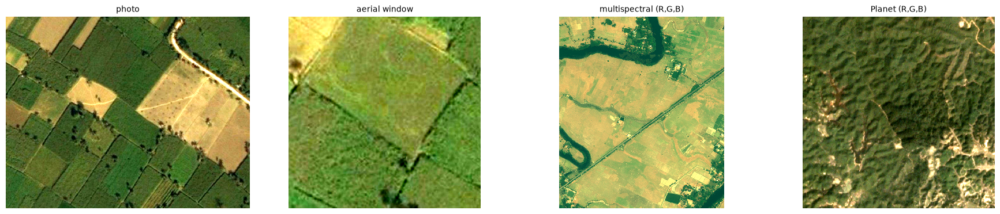

In [3]:
show([photo, aerial, multi.isel(band=[4, 2, 1]), planet.isel(band=[2, 1, 0])],  # the four images in true colour
     ["photo", "aerial window", "multispectral (R,G,B)", "Planet (R,G,B)"], size=4.5)

The multispectral image has large no-data areas (NaN, drawn white). All filters and statistics below skip them.

Write and read back a GeoTIFF to check that the CRS and transform survive:


In [7]:
import tempfile  # temporary folder for the round trip

with tempfile.TemporaryDirectory() as tmp:  # a folder that is deleted afterwards
    # write the multispectral window as a GeoTIFF
    path = ip.write_image(multi, Path(tmp) / "multi.tif", dtype="float32", nodata=np.nan)
    back = ip.read_image(path)  # and read it back
# compare CRS, bounds and values
print("same CRS:", back.rio.crs == multi.rio.crs, "| same bounds:", np.allclose(back.rio.bounds(), multi.rio.bounds()),
      "| same values:", np.allclose(back.values, multi.values, equal_nan=True))

same CRS: True | same bounds: True | same values: True


## Color spaces

### Gray (luminance)

A weighted sum of the red, green and blue bands,

$$Y = w_R R + w_G G + w_B B,\qquad (w_R,w_G,w_B)=(0.2125,\,0.7154,\,0.0721),$$

the Rec. 709 luminance weights used by scikit-image (`rgb2gray`). OpenCV's `COLOR_BGR2GRAY` uses $(0.299, 0.587, 0.114)$; pass `weights=` to switch. The weights sum to 1, so $Y$ stays in the input range. Gray images are the usual input to edge and texture operators. Function: `to_gray`.

### HSV

With $R,G,B\in[0,1]$, $M=\max(R,G,B)$, $m=\min(R,G,B)$ and chroma $C=M-m$:

$$V=M,\qquad S=\begin{cases}0 & M=0\\ C/M & \text{otherwise}\end{cases},\qquad
H=\frac{1}{6}\begin{cases} \dfrac{G-B}{C}\bmod 6 & M=R\\[4pt] \dfrac{B-R}{C}+2 & M=G\\[4pt] \dfrac{R-G}{C}+4 & M=B\end{cases}$$

(in $[0,1)$ here). Hue is the color angle, saturation the purity, and value the brightness. Hue and saturation are less sensitive to illumination than raw RGB, which helps separate vegetation (green hue, high saturation) from bare soil (orange hue, low saturation). Functions: `rgb_to_hsv`, `hsv_to_rgb`.

### CIE L\*a\*b\*

A perceptually uniform space. With linearized RGB converted to CIE XYZ (D65 white point $X_n,Y_n,Z_n$) and $f(t)=t^{1/3}$ for $t>(6/29)^3$ (linear otherwise):

$$L^*=116\,f(Y/Y_n)-16,\quad a^*=500\,[f(X/X_n)-f(Y/Y_n)],\quad b^*=200\,[f(Y/Y_n)-f(Z/Z_n)].$$

Euclidean distance in $(L^*,a^*,b^*)$ approximates perceived color difference $\Delta E$, so k-means in Lab separates colors more evenly than in RGB. Function: `rgb_to_lab`.

`to_uint8` rescales to 0-255 for display or file export.


HSV round-trip max error: 4.2775098019198765e-08


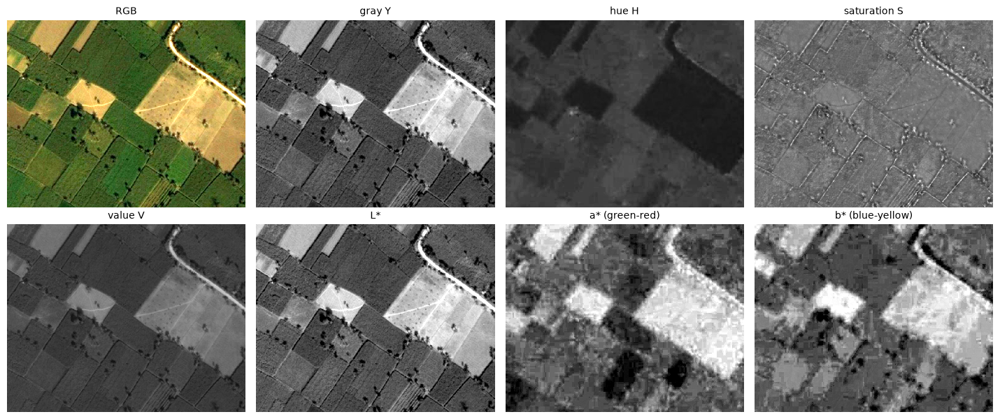

In [8]:
gray = ip.to_gray(photo)  # grey-scale luminance
hsv = ip.rgb_to_hsv(photo)  # hue, saturation, value
lab = ip.rgb_to_lab(photo)  # CIE L*a*b* (lightness and two colour axes)
back = ip.hsv_to_rgb(hsv)  # back from HSV to RGB
# the round trip is lossless up to rounding
print("HSV round-trip max error:", float(np.abs(back.values - photo.values / 255).max()))

# every colour component side by side
show([photo, gray, hsv.isel(band=0), hsv.isel(band=1), hsv.isel(band=2), lab.isel(band=0), lab.isel(band=1), lab.isel(band=2)],
     ["RGB", "gray Y", "hue H", "saturation S", "value V", "L*", "a* (green-red)", "b* (blue-yellow)"], ncols=4, size=3.6)

Hue separates the green fields from the brown soil and the track. The $a^*$ band is negative on vegetation and positive on soil, a one-band proxy for greenness that needs no infrared.


## Geometric transformations

A geometric transform maps output pixel coordinates $\mathbf{p}'=(c',r')$ to input coordinates $\mathbf{p}=T^{-1}\mathbf{p}'$ and **samples** the input there (inverse mapping, so there are no holes). Because $\mathbf{p}$ is rarely an integer, a value is interpolated.

### Interpolation

Let $\mathbf p=(x,y)$, $x_0=\lfloor x\rfloor$, $y_0=\lfloor y\rfloor$, $\delta_x=x-x_0$, $\delta_y=y-y_0$.

* Nearest (`order=0`): $I'(\mathbf p)=I(\operatorname{round}x,\operatorname{round}y)$. Keeps original values, so use it for class maps.
* Bilinear (`order=1`):
$$I'=(1-\delta_x)(1-\delta_y)I_{00}+\delta_x(1-\delta_y)I_{10}+(1-\delta_x)\delta_yI_{01}+\delta_x\delta_yI_{11}.$$
* Bicubic (`order=3`): a cubic convolution over a $4\times4$ neighbourhood, sharper than bilinear.

When shrinking an image by a factor $s>1$, high frequencies alias. `resize` applies a Gaussian pre-filter with $\sigma=(s-1)/2$ (`anti_aliasing=True`, the default when the output is smaller).

### Resize, rescale and block averaging

`resize(img, shape=(h, w))` or `scale=`; give `None` for one side to keep the aspect ratio. `rescale(img, f)` scales both sides by $f$. `downscale_local_mean(img, (f_y, f_x))` averages non-overlapping blocks,

$$I'(r,c)=\frac{1}{f_yf_x}\sum_{i=0}^{f_y-1}\sum_{j=0}^{f_x-1}I(f_yr+i,\;f_xc+j),$$

the exact model of a coarser sensor with the same spectral response. For a georeferenced input the new pixel size is $a'=a\,W/W'$, $e'=e\,H/H'$ and the extent is unchanged.

### Rotation, shift and flip

A rotation by $\theta$ (counter-clockwise) about the centre $(c_x,c_y)$ and a translation by $(t_x,t_y)$ are affine maps in homogeneous coordinates,

$$\begin{pmatrix}c'\\r'\\1\end{pmatrix}=\begin{pmatrix}\cos\theta&\sin\theta&(1-\cos\theta)c_x-\sin\theta\,c_y\\-\sin\theta&\cos\theta&\sin\theta\,c_x+(1-\cos\theta)c_y\\0&0&1\end{pmatrix}\begin{pmatrix}c\\r\\1\end{pmatrix},\qquad
\begin{pmatrix}c'\\r'\end{pmatrix}=\begin{pmatrix}c+t_x\\r+t_y\end{pmatrix}.$$

(`rotate` with `resize_output=True` enlarges the canvas to hold the whole rotated image: $W'=W|\cos\theta|+H|\sin\theta|$.) Flips reverse an axis: $I'(r,c)=I(r,W-1-c)$. Corners with no source pixel are filled with `cval` (NaN by default, so they show as no-data).

### General affine and perspective warps

An affine transform $M$ (6 parameters) preserves parallel lines (rotation, scale, shear, translation):

$$\begin{pmatrix}c'\\r'\end{pmatrix}=\begin{pmatrix}m_{11}&m_{12}&m_{13}\\m_{21}&m_{22}&m_{23}\end{pmatrix}\begin{pmatrix}c\\r\\1\end{pmatrix}.$$

A perspective (homography) transform $H$ (8 parameters) maps four points to four points and models a tilted camera:

$$\begin{pmatrix}u\\v\\w\end{pmatrix}=H\begin{pmatrix}c\\r\\1\end{pmatrix},\qquad c'=\frac uw,\quad r'=\frac vw .$$

$H$ is estimated from the four correspondences by solving the resulting linear system (direct linear transform). Functions: `affine_transform`, `perspective_transform` (the OpenCV `warpAffine` / `getPerspectiveTransform` + `warpPerspective` workflow). Crop is plain slicing, $I'(r,c)=I(r_0+r,c_0+c)$ (`crop(img, window=...)` or `bounds=` in map units).


In [9]:
small = ip.resize(photo, (305, 387))                 # keeps dtype, georeferencing and extent
fixed = ip.resize(photo, (300, None))                # height 300, width from aspect ratio
half = ip.rescale(photo, 0.5, order=3)  # half size with bicubic interpolation
blocks = ip.downscale_local_mean(photo, (4, 4))  # average of each 4 x 4 block
# output sizes
print("resize:", small.shape, "| keep aspect:", fixed.shape, "| rescale 0.5 bicubic:", half.shape, "| 4x4 block mean:", blocks.shape)

# The aerial window is georeferenced: block-averaging coarsens the pixel but keeps the extent
coarse = ip.downscale_local_mean(aerial, (8, 8))
# pixel size before and after
print("aerial pixel size before/after (m):", aerial.rio.resolution()[0], "->", coarse.rio.resolution()[0])
# the extent is unchanged
print("same extent:", np.allclose(aerial.rio.bounds(), coarse.rio.bounds(), atol=1e-4))

resize: (3, 305, 387) | keep aspect: (3, 300, 381) | rescale 0.5 bicubic: (3, 305, 388) | 4x4 block mean: (3, 153, 194)
aerial pixel size before/after (m): 0.01795572066664867 -> 0.14364576525986195
same extent: True


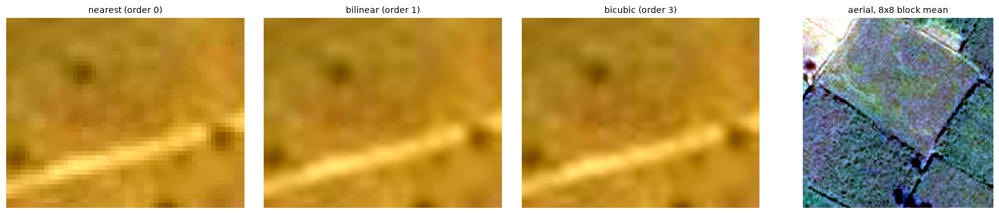

In [7]:
# Interpolation orders on a 6x zoom of a small patch
patch = ip.crop(photo, (250, 290, 480, 530))
# three interpolation orders and the block-averaged aerial image
show([ip.resize(patch, scale=6, order=o) for o in (0, 1, 3)] + [ip.stretch(coarse)],
     ["nearest (order 0)", "bilinear (order 1)", "bicubic (order 3)", "aerial, 8x8 block mean"], size=4.2)

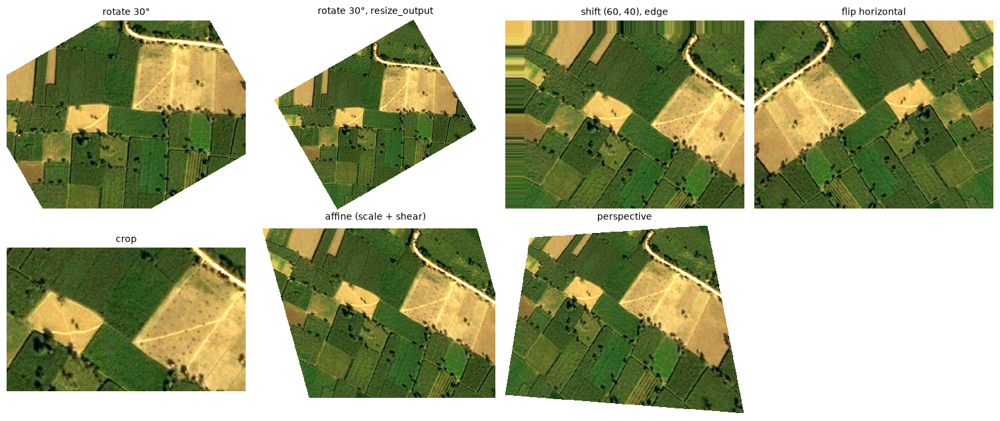

rotated canvas: (3, 915, 976) | cropped x starts at 150.5


In [10]:
rot = ip.rotate(photo, 30)  # rotate by 30 degrees (corners cut off)
rot_big = ip.rotate(photo, 30, resize_output=True)  # rotate and enlarge the canvas to keep the corners
sh = ip.shift(photo, dx=60, dy=40, mode="edge")  # shift 60 px right and 40 px down, repeating the edge
fl = ip.flip(photo, "horizontal")  # mirror left-right
cr = ip.crop(photo, (100, 400, 150, 650))  # rows 100-400, columns 150-650

H, W = photo.shape[1:]  # image height and width
M = np.array([[0.9, 0.25, 20], [0.0, 0.9, 10]])      # scale, shear, translate
aff = ip.affine_transform(photo, M)  # apply the affine matrix
src = [(0, 0), (W - 1, 0), (W - 1, H - 1), (0, H - 1)]  # the four image corners
dst = [(80, 40), (W - 120, 0), (W - 1, H - 1), (0, H - 60)]  # where those corners should go
persp = ip.perspective_transform(photo, src, dst)  # perspective warp from corners to corners

show([rot, rot_big, sh, fl, cr, aff, persp],  # all transforms side by side
     ["rotate 30°", "rotate 30°, resize_output", "shift (60, 40), edge", "flip horizontal", "crop", "affine (scale + shear)", "perspective"],
     ncols=4, size=3.8)
# size of the enlarged canvas; x of the crop
print("rotated canvas:", rot_big.shape, "| cropped x starts at", float(cr.x[0]) if "x" in cr.coords else None)

## Radiometric operations

Radiometric operations change pixel **values** without moving pixels. They use only the gray-level distribution, so they are the first step for display and for matching images from different dates or sensors.

### Linear contrast stretch

With the $p_{low}$ and $p_{high}$ percentiles $L$ and $U$ of a band (default 2 and 98),

$$I'=\operatorname{clip}\!\Big(\frac{I-L}{U-L},\,0,\,1\Big)\,(o_{max}-o_{min})+o_{min}.$$

Clipping the tails prevents a few very bright or dark pixels (clouds, shadows) from compressing the rest of the histogram. Function: `stretch(img, percentiles, out_range, per_band)`.

### Gamma and brightness/contrast

On values scaled to $[0,1]$:

$$I'=g\,I^{\gamma},\qquad\qquad I'=\operatorname{clip}(\alpha I+\beta,0,1).$$

$\gamma<1$ brightens dark areas (it expands dark values: $dI'/dI=\gamma I^{\gamma-1}$ is large near 0), $\gamma>1$ darkens. $\alpha$ is the contrast gain and $\beta$ the brightness offset. Functions: `adjust_gamma`, `adjust_brightness_contrast`.

### Histogram and equalization

The histogram counts values in $K$ bins, $h(k)=\#\{I=k\}$; the normalized histogram $p(k)=h(k)/N$ and the cumulative distribution $F(k)=\sum_{j\le k}p(j)$. **Histogram equalization** maps each value through its own CDF,

$$I'=F(I),$$

which makes the output distribution approximately uniform and uses the full dynamic range. `histogram` returns counts and bin edges; `equalize_hist` applies the mapping per band.

### CLAHE

Contrast-Limited Adaptive Histogram Equalization applies the mapping inside local tiles. The histogram of each tile is clipped at a limit $\beta$ and the clipped excess is redistributed,

$$h_{clip}(k)=\min\big(h(k),\beta\big)+\frac{1}{K}\sum_j\max\big(h(j)-\beta,0\big),$$

then the CDF of $h_{clip}$ is used and values are bilinearly blended between neighbouring tiles to avoid seams. Clipping limits noise amplification in flat regions. Function: `equalize_adapthist(kernel_size, clip_limit)`.

### Histogram matching

To make image $A$ look like reference $R$, each value $v$ is mapped to the value with the same cumulative probability,

$$I'=F_R^{-1}\big(F_A(I)\big).$$

This normalizes illumination and sensor offsets before change detection or when training on one scene and applying to another. Function: `match_histograms(img, reference)`.


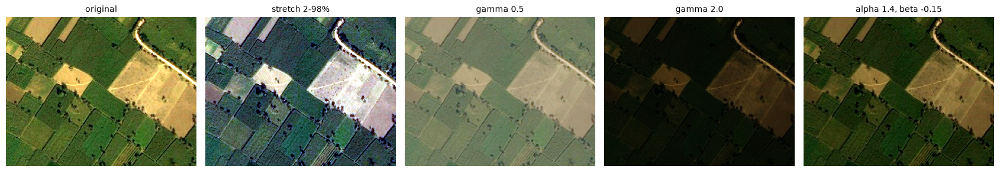

In [11]:
st = ip.stretch(photo)                                   # 2-98 percent per band
g_bright = ip.adjust_gamma(photo, 0.5)  # gamma < 1 brightens dark tones
g_dark = ip.adjust_gamma(photo, 2.0)  # gamma > 1 darkens
bc = ip.adjust_brightness_contrast(photo, alpha=1.4, beta=-0.15)  # contrast x1.4, brightness -0.15
show([photo, st, g_bright, g_dark, bc],  # compare them
     ["original", "stretch 2-98%", "gamma 0.5", "gamma 2.0", "alpha 1.4, beta -0.15"], ncols=5, size=3.4)

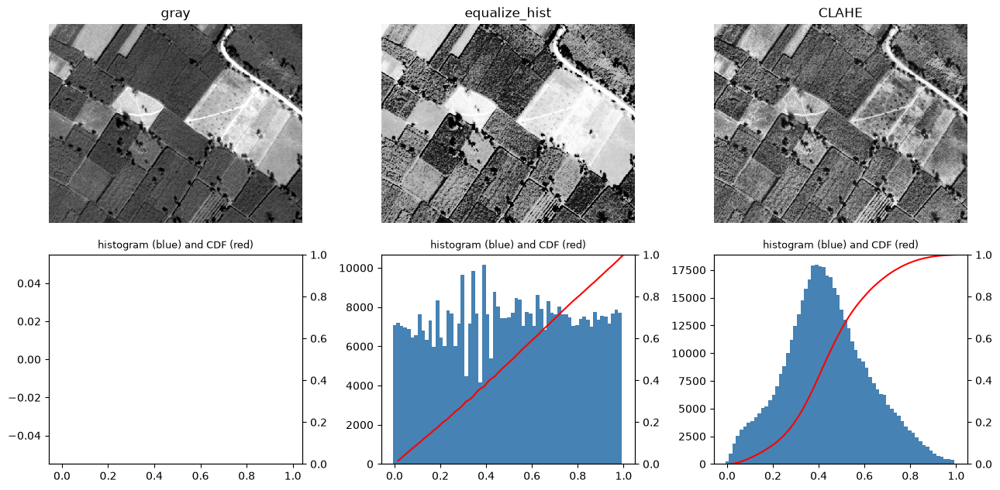

In [12]:
eq = ip.equalize_hist(gray)  # global histogram equalisation
# contrast-limited adaptive equalisation (CLAHE)
clahe = ip.equalize_adapthist(gray, kernel_size=64, clip_limit=0.02)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))  # images above, histograms below
# top row: the three images
for ax, (im, t) in zip(axes[0], [(gray, "gray"), (eq, "equalize_hist"), (clahe, "CLAHE")]):
    ax.imshow(to_show(im), cmap="gray", vmin=0, vmax=1); ax.set_title(t); ax.axis("off")  # draw the image
# bottom row: their histograms
for ax, (im, t) in zip(axes[1], [(gray, "gray"), (eq, "equalize_hist"), (clahe, "CLAHE")]):
    h = ip.histogram(im, bins=64, value_range=(0, 1))  # 64-bin histogram on 0-1
    ax.bar(h["edges"][:-1], h["counts"][0], width=1 / 64, color="steelblue")  # the counts as bars
    cdf = np.cumsum(h["counts"][0]) / h["counts"][0].sum()  # cumulative distribution
    ax2 = ax.twinx(); ax2.plot(h["edges"][1:], cdf, "r-"); ax2.set_ylim(0, 1)  # the CDF on a second axis
    ax.set_title("histogram (blue) and CDF (red)", fontsize=9)  # panel title
plt.tight_layout(); plt.show()  # arrange and draw

Equalization flattens the histogram and straightens its CDF; CLAHE gets a similar contrast gain without the global brightening of dark scenes. Histogram matching: bring the Planet near-infrared band to the statistics of the multispectral NIR band.


      Planet NIR  multispectral NIR (reference)  Planet NIR matched
mean      2665.0                          682.1               681.7
std        528.5                          139.3               139.2
p5        1782.0                          280.0               279.6
p95       3498.0                          800.0               799.7


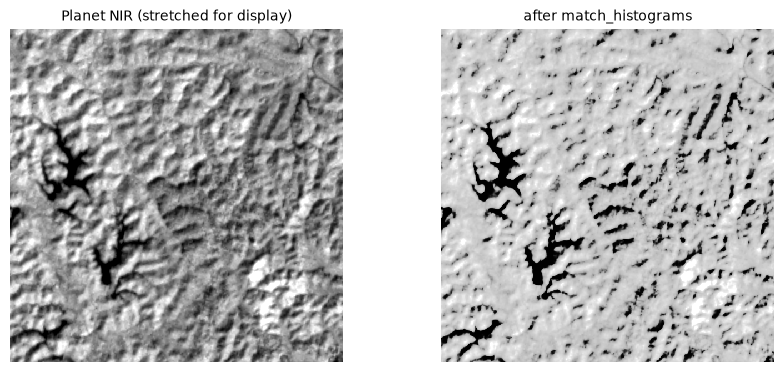

In [13]:
planet_nir = planet.isel(band=[3])  # Planet NIR band (kept as a 1-band stack)
multi_nir = multi.isel(band=[6])  # NIR band of the multispectral image
matched = ip.match_histograms(planet_nir, multi_nir)  # Planet NIR mapped onto the multispectral histogram

def stats(x):  # summary statistics of an image
    v = np.asarray(x.values if hasattr(x, "values") else x, dtype=float)  # values as floats
    # mean, spread and 5th / 95th percentiles
    return {"mean": np.nanmean(v), "std": np.nanstd(v), "p5": np.nanpercentile(v, 5), "p95": np.nanpercentile(v, 95)}

# before and after matching, next to the reference
print(pd.DataFrame({"Planet NIR": stats(planet_nir), "multispectral NIR (reference)": stats(multi_nir),
                    "Planet NIR matched": stats(matched)}).round(1))
# the two images
show([planet_nir, matched], ["Planet NIR (stretched for display)", "after match_histograms"], size=4.5)

## Thresholding

Thresholding splits an image into foreground and background, $B(r,c)=\mathbf 1[I(r,c)>T]$. The choice of $T$ is the whole problem.

### Otsu

Otsu chooses $T$ to maximize the **between-class variance** of the two groups it creates. With normalized histogram $p_i$, class weights $\omega_0(T)=\sum_{i\le T}p_i$, $\omega_1=1-\omega_0$ and class means $\mu_0,\mu_1$,

$$T^*=\arg\max_T\ \sigma_B^2(T),\qquad \sigma_B^2(T)=\omega_0(T)\,\omega_1(T)\,\big[\mu_0(T)-\mu_1(T)\big]^2 .$$

Since total variance is fixed, this equals minimizing the within-class variance. It works best for a bimodal histogram.

### Other global rules

* **Li**: minimizes the cross entropy between the image and its thresholded version.
* **Triangle**: draws a line from the histogram peak to the far end and picks the point of maximum distance from it; good for one dominant peak (water bodies, shadows).
* **Yen**: maximizes an entropic correlation criterion.
* **Isodata**: iterates $T=\tfrac12(\mu_0(T)+\mu_1(T))$ to a fixed point.
* **Mean**: $T=\bar I$.

### Local (adaptive) threshold

For uneven illumination, the threshold follows a local statistic over a $w\times w$ block:

$$B(r,c)=\mathbf 1\big[I(r,c)>\mu_w(r,c)-\text{offset}\big].$$

Function: `threshold(img, method, block_size, offset, return_value)` returns a `uint8` 0/1 mask (NaN pixels are 0).

### Example: vegetation mask from NDVI

The normalized difference vegetation index $\mathrm{NDVI}=\dfrac{\rho_{NIR}-\rho_{Red}}{\rho_{NIR}+\rho_{Red}}\in[-1,1]$ is high for photosynthesizing vegetation.


NDVI range: 0.08609271794557571 0.7852820754051208


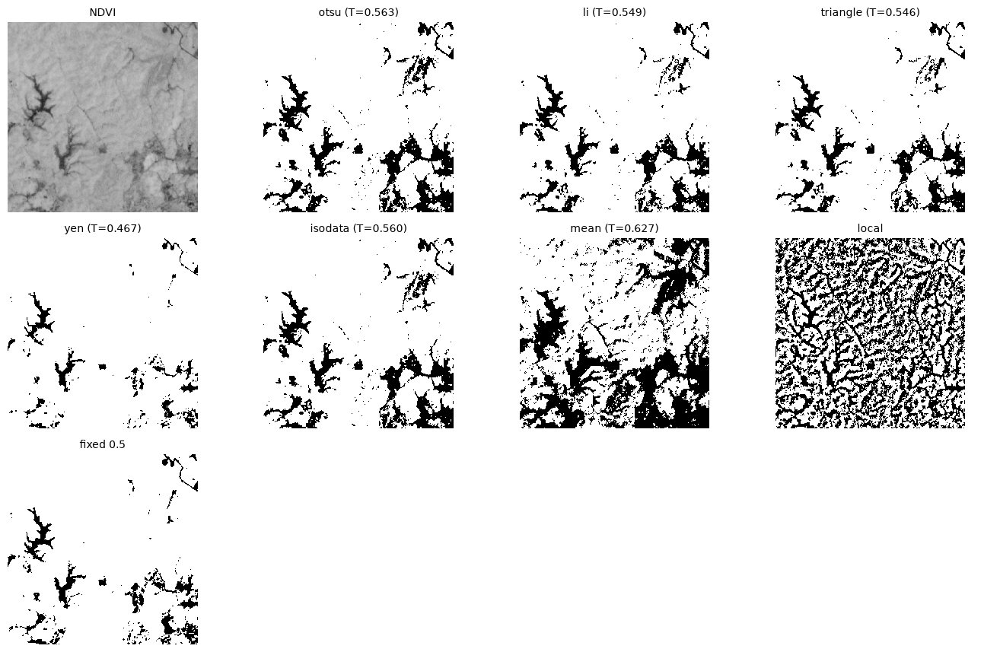

In [14]:
red = planet.sel(band=3).astype("float64")  # red band as float
nir = planet.sel(band=4).astype("float64")  # NIR band as float
ndvi = ((nir - red) / (nir + red)).expand_dims(band=[1]).astype("float32")  # NDVI as a one-band stack
print("NDVI range:", float(ndvi.min()), float(ndvi.max()))  # its range

masks, vals = {}, {}  # masks and threshold values
for m in ["otsu", "li", "triangle", "yen", "isodata", "mean"]:  # six global thresholding methods
    masks[m], vals[m] = ip.threshold(ndvi, m, return_value=True)  # mask and threshold of each
masks["local"] = ip.threshold(ndvi, "local", block_size=51)  # local (adaptive) threshold in 51 px blocks
masks["fixed 0.5"] = ip.threshold(ndvi, 0.5)  # a fixed threshold for comparison

# NDVI and every mask
show([ndvi] + list(masks.values()), ["NDVI"] + [f"{k}" + (f" (T={vals[k][0]:.3f})" if k in vals else "") for k in masks],
     ncols=4, size=3.4)

Otsu by hand T=0.563   threshold(...,'otsu') T=0.563


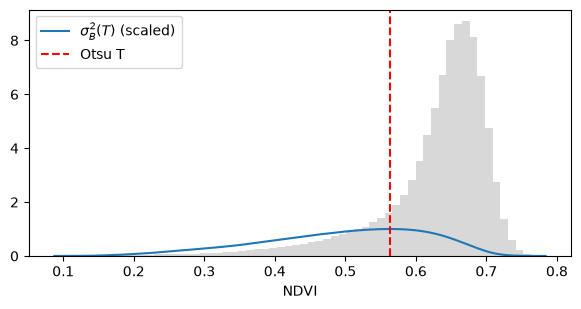

In [15]:
# Otsu by hand: maximize the between-class variance over histogram bins
v = ndvi.values.ravel()
h = ip.histogram(ndvi, bins=256)  # 256-bin NDVI histogram
p = h["counts"][0] / h["counts"][0].sum()  # share of pixels in each bin
centers = 0.5 * (h["edges"][:-1] + h["edges"][1:])  # bin centres
w0 = np.cumsum(p); w1 = 1 - w0  # weight of class 0 and class 1 for every threshold
mu = np.cumsum(p * centers); mu_t = mu[-1]  # cumulative mean and the total mean
with np.errstate(divide="ignore", invalid="ignore"):  # ignore division by zero at the ends
    sigma_b = (mu_t * w0 - mu) ** 2 / (w0 * w1)  # between-class variance for every threshold
t_manual = centers[np.nanargmax(sigma_b)]  # the threshold that maximises it
# compare with the library result
print(f"Otsu by hand T={t_manual:.3f}   threshold(...,'otsu') T={vals['otsu'][0]:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))  # one panel
# between-class variance curve
ax.plot(centers, sigma_b / np.nanmax(sigma_b), label=r"$\sigma_B^2(T)$ (scaled)")
ax.hist(v, bins=64, density=True, alpha=.3, color="grey")  # NDVI histogram behind it
ax.axvline(t_manual, color="r", ls="--", label="Otsu T")  # the chosen threshold
ax.set_xlabel("NDVI"); ax.legend(); plt.show()  # label and draw

## Filtering and denoising

### Convolution (spatial filtering)

A linear filter replaces each pixel by a weighted sum of its neighbours. With a $(2k+1)\times(2k+1)$ kernel $K$,

$$I'(r,c)=\sum_{i=-k}^{k}\sum_{j=-k}^{k}K(i,j)\,I(r+i,\,c+j).$$

(This is correlation, which is what OpenCV `filter2D` computes; for symmetric kernels it equals convolution.) Borders are reflected. `convolve(img, kernel)` accepts an array or a name in `ip.KERNELS`: `identity`, `box`, `sharpen`, `sharpen_strong`, `laplacian`, `emboss`.

| Kernel | Matrix | Effect |
|---|---|---|
| identity | $\begin{pmatrix}0&0&0\\0&1&0\\0&0&0\end{pmatrix}$ | unchanged |
| box | $\tfrac19\begin{pmatrix}1&1&1\\1&1&1\\1&1&1\end{pmatrix}$ | mean blur |
| sharpen | $\begin{pmatrix}0&-1&0\\-1&5&-1\\0&-1&0\end{pmatrix}$ | $I+\!(-\nabla^2 I)$ |
| laplacian | $\begin{pmatrix}0&1&0\\1&-4&1\\0&1&0\end{pmatrix}$ | second derivative |

### Mean and Gaussian blur

The box filter averages a $w\times w$ window. The Gaussian weights neighbours by distance,

$$G_\sigma(i,j)=\frac{1}{2\pi\sigma^2}\exp\!\Big(-\frac{i^2+j^2}{2\sigma^2}\Big),$$

which is separable ($G_\sigma(i,j)=g(i)g(j)$) and so costs $O(k)$ instead of $O(k^2)$ per pixel. It suppresses noise by $\approx 1/(2\sqrt\pi\,\sigma)$ in standard deviation for white noise, at the cost of blurring edges. Functions: `mean_blur(size)`, `gaussian_blur(sigma)`.

### Median filter

$I'(r,c)=\operatorname{median}\{I(r+i,c+j)\}$. A nonlinear filter that removes salt-and-pepper outliers and SAR speckle spikes while keeping edges, because a single extreme value cannot move the median. Function: `median_blur(size)`.

### Bilateral filter

A Gaussian weighted by **both** distance and value difference,

$$I'(\mathbf p)=\frac{1}{W_{\mathbf p}}\sum_{\mathbf q}I(\mathbf q)\,\exp\!\Big(-\frac{\|\mathbf p-\mathbf q\|^2}{2\sigma_s^2}\Big)\exp\!\Big(-\frac{(I(\mathbf p)-I(\mathbf q))^2}{2\sigma_c^2}\Big),$$

so pixels across an edge (large $|I(\mathbf p)-I(\mathbf q)|$) get small weights and edges survive. $\sigma_s$ is `sigma_spatial` (pixels) and $\sigma_c$ is `sigma_color`. Function: `bilateral_denoise`.

### Total-variation denoising

Chambolle's method solves

$$\hat I=\arg\min_u\ \tfrac12\|u-I\|_2^2+\lambda\,\mathrm{TV}(u),\qquad \mathrm{TV}(u)=\sum_{r,c}\|\nabla u(r,c)\|_2,$$

which penalizes total gradient, flattening noise inside regions but keeping jumps (a piecewise-constant prior). `weight` is $\lambda$: larger is smoother. Function: `tv_denoise`.

### Sharpening and unsharp masking

The Laplacian-based sharpen is $I'=I-\nabla^2I$ (`sharpen`, with `strength` blending toward identity). **Unsharp masking** adds the difference between the image and a blurred copy,

$$I'=I+a\,\big(I-G_\sigma*I\big),$$

a high-pass boost with gain $a$ (`amount`) and scale $\sigma$ (`radius`). Function: `unsharp_mask`.

### Noise models and PSNR

`add_noise` works on values in $[0,1]$: Gaussian $I'=I+\mathcal N(0,\sigma^2)$, speckle $I'=I+I\,\mathcal N(0,\sigma^2)$ (multiplicative, as in SAR), and salt / pepper / s&p (a fraction of pixels set to 1 and/or 0). A denoiser is scored against the clean image by

$$\mathrm{MSE}=\frac{1}{N}\sum(I-\hat I)^2,\qquad \mathrm{PSNR}=10\log_{10}\frac{1}{\mathrm{MSE}}\ \text{dB}\quad(\text{peak}=1).$$


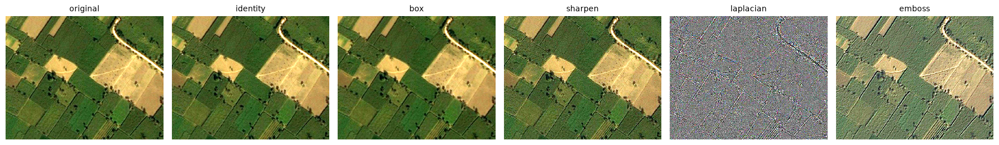

In [16]:
names = ["identity", "box", "sharpen", "laplacian", "emboss"]  # standard 3 x 3 kernels
# the photo filtered with each
show([photo] + [ip.convolve(photo, k) for k in names], ["original"] + names, ncols=6, size=3.0)

In [17]:
def psnr(a, b):  # peak signal-to-noise ratio of b against a
    # both as float arrays
    a = np.asarray(a.values if hasattr(a, "values") else a, float); b = np.asarray(b.values if hasattr(b, "values") else b, float)
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))  # PSNR in dB for values in 0-1

clean = ip.stretch(gray, percentiles=(0, 100))                # gray in [0, 1]
rows, imgs, titles = [], [], []  # scores, images and titles
for noise, amount in [("gaussian", 0.10), ("s&p", 0.05), ("speckle", 0.25)]:  # three noise types
    noisy = ip.add_noise(clean, noise, amount, seed=0)  # add noise to the clean image
    out = {  # five denoising filters
        "noisy": noisy,
        "mean 5": ip.mean_blur(noisy, 5),
        "gaussian s=1.5": ip.gaussian_blur(noisy, 1.5),
        "median 5": ip.median_blur(noisy, 5),
        "bilateral": ip.bilateral_denoise(noisy, sigma_color=0.3, sigma_spatial=2),
        "TV 0.15": ip.tv_denoise(noisy, weight=0.15),
    }
    # PSNR of each result
    rows.append({k: psnr(clean, v) for k, v in out.items()} | {"noise": f"{noise} ({amount})"})
    imgs += [out["noisy"], out["median 5"], out["bilateral"], out["TV 0.15"]]  # keep four images for display
    titles += [f"{noise}: noisy", "median 5", "bilateral", "TV 0.15"]  # and their titles
print("PSNR in dB (higher is better)")  # table header
pd.DataFrame(rows).set_index("noise").round(2)  # PSNR table

PSNR in dB (higher is better)


,noisy,mean 5,gaussian s=1.5,median 5,bilateral,TV 0.15
noise,,,,,,
gaussian (0.1),20.04,32.08,32.50,30.74,27.66,32.55
s&p (0.05),18.36,30.33,30.71,37.48,25.36,27.35
speckle (0.25),21.22,32.71,33.10,31.57,27.54,32.85


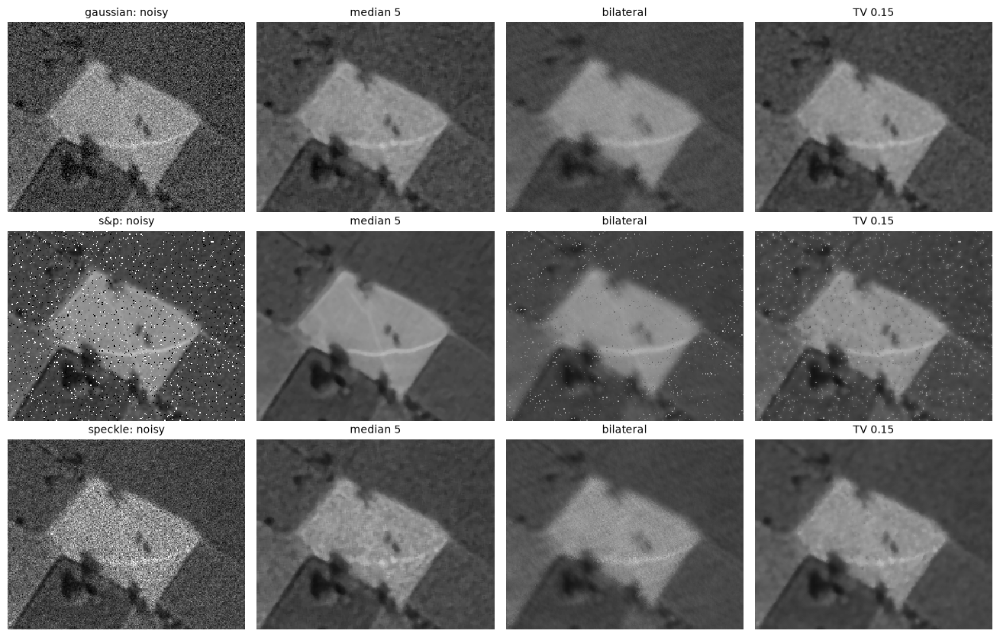

In [18]:
# a zoomed crop of every kept image
show([ip.crop(i, (150, 350, 150, 400)) for i in imgs], titles, ncols=4, size=3.3)

The median filter wins by a wide margin on salt-and-pepper noise (about +7 dB over the mean filter). For Gaussian and speckle noise the Gaussian blur and TV filters score highest, and the bilateral filter, tuned here to keep edges, removes less noise in a single pass (raise `sigma_color` to smooth more). No filter is ideal for multiplicative speckle; SAR needs speckle-specific filters such as Lee or Frost. Now sharpening:


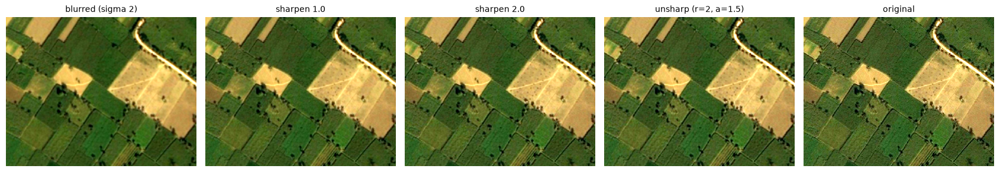

In [19]:
soft = ip.gaussian_blur(photo, 2.0)  # blur the photo first
# compare sharpening strengths with the original
show([soft, ip.sharpen(soft, 1.0), ip.sharpen(soft, 2.0), ip.unsharp_mask(soft, radius=2.0, amount=1.5), photo],
     ["blurred (sigma 2)", "sharpen 1.0", "sharpen 2.0", "unsharp (r=2, a=1.5)", "original"], ncols=5, size=3.4)

## Edge detection

An edge is a place where the intensity changes quickly, i.e. where the gradient magnitude

$$|\nabla I|=\sqrt{G_x^2+G_y^2},\qquad \theta=\operatorname{atan2}(G_y,G_x)$$

is large. The operators differ in the kernels that estimate $G_x,G_y$.

| Operator | $G_x$ kernel | Notes |
|---|---|---|
| Roberts | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ ($2\times2$ diagonal) | fast, noise sensitive |
| Prewitt | $\begin{pmatrix}-1&0&1\\-1&0&1\\-1&0&1\end{pmatrix}$ | box smoothing across the gradient |
| Sobel | $\begin{pmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{pmatrix}$ | Gaussian-like smoothing, the standard |
| Scharr | $\begin{pmatrix}-3&0&3\\-10&0&10\\-3&0&3\end{pmatrix}$ | better rotational symmetry |

$G_y$ is the transpose. `sobel_h` and `sobel_v` return the signed responses (horizontal edges, vertical edges); `edges(img, method)` returns the magnitude.

### Laplacian

The second derivative $\nabla^2I=\partial^2I/\partial x^2+\partial^2I/\partial y^2$, with the kernel above; edges are its zero crossings, and `edges(img, "laplacian")` returns $|\nabla^2 I|$. It responds to blobs and lines and is very noise sensitive, so smooth first.

### Canny

1. Smooth with a Gaussian of scale `sigma`.
2. Compute $|\nabla I|$ and $\theta$.
3. **Non-maximum suppression**: keep a pixel only if its magnitude is a local maximum along $\theta$, which thins edges to one pixel.
4. **Hysteresis**: pixels above `high` are edges; pixels between `low` and `high` are kept only if connected to a strong edge.

`edges(img, "canny", sigma, low, high)` returns a 0/1 `uint8` map; larger `sigma` finds fewer, more important edges.


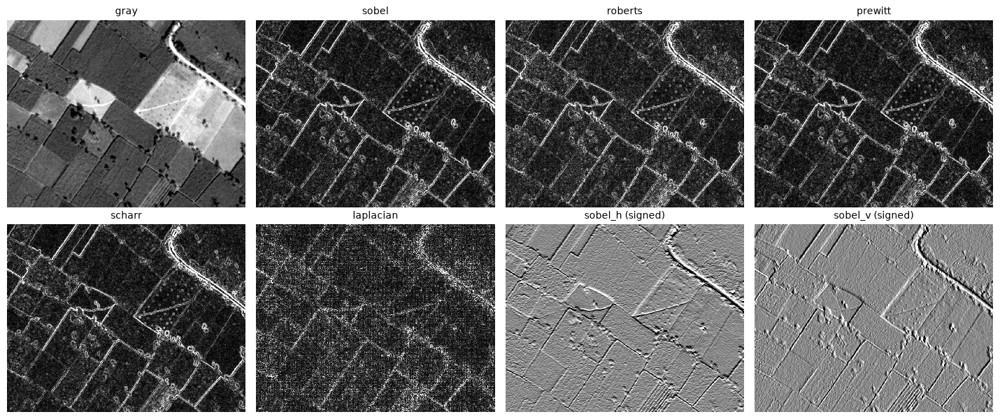

In [18]:
ops = ["sobel", "roberts", "prewitt", "scharr", "laplacian"]  # gradient operators
# the edge magnitude of each, and the signed Sobel components
show([gray] + [ip.edges(gray, m) for m in ops] + [ip.sobel_h(gray), ip.sobel_v(gray)],
     ["gray"] + ops + ["sobel_h (signed)", "sobel_v (signed)"], ncols=4, size=3.6)

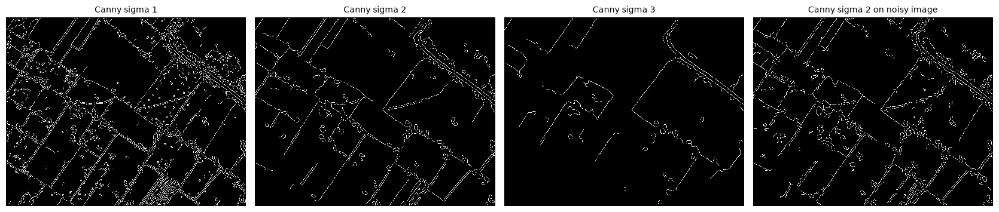

In [19]:
cans = [ip.edges(gray, "canny", sigma=s) for s in (1, 2, 3)]  # Canny edges at three smoothing scales
cans.append(ip.edges(ip.add_noise(gray, "gaussian", 0.1, seed=0), "canny", sigma=2))  # Canny on a noisy image
# compare them
show(cans, ["Canny sigma 1", "Canny sigma 2", "Canny sigma 3", "Canny sigma 2 on noisy image"], size=4.2)

Field boundaries and the track show up at sigma 2-3, while sigma 1 also traces crop rows. This is the key trade-off for object-based classification: edges at the right scale delimit objects.


## Morphology

Morphology probes an image with a small **structuring element** $B$ (square, disk or cross). For gray images:

$$(I\ominus B)(\mathbf p)=\min_{\mathbf b\in B}I(\mathbf p+\mathbf b)\ \text{(erosion)},\qquad (I\oplus B)(\mathbf p)=\max_{\mathbf b\in B}I(\mathbf p+\mathbf b)\ \text{(dilation)}.$$

For binary masks erosion shrinks objects and removes specks, dilation grows them and fills gaps. Compositions:

| Operation | Definition | Use |
|---|---|---|
| opening | $I\circ B=(I\ominus B)\oplus B$ | remove small bright objects (noise) |
| closing | $I\bullet B=(I\oplus B)\ominus B$ | fill small holes and gaps |
| gradient | $(I\oplus B)-(I\ominus B)$ | object outlines |
| top-hat | $I-(I\circ B)$ | small bright details |
| black-hat | $(I\bullet B)-I$ | small dark details |

`morphology(img, op, size, shape)` implements all seven. `remove_small_objects(mask, min_size)` deletes connected components smaller than `min_size` pixels, equal to opening by area.


vegetation pixels: 305541 -> open 303436 -> close 311485 -> remove small 311057


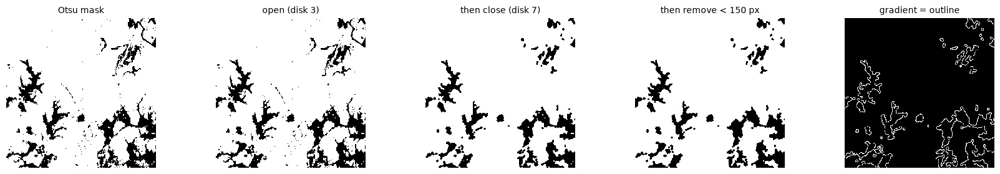

In [20]:
veg = masks["otsu"]  # Otsu vegetation mask from NDVI
opened = ip.morphology(veg, "open", 3, "disk")  # opening removes small specks
closed = ip.morphology(opened, "close", 7, "disk")  # closing fills small holes
clean_mask = ip.remove_small_objects(closed, min_size=150)  # drop blobs smaller than 150 px
# vegetation pixels after each step
print("vegetation pixels:", int(veg.sum()), "-> open", int(opened.sum()), "-> close", int(closed.sum()), "-> remove small", int(clean_mask.sum()))
show([veg, opened, closed, clean_mask, ip.morphology(clean_mask, "gradient", 3)],  # every step and the outline
     ["Otsu mask", "open (disk 3)", "then close (disk 7)", "then remove < 150 px", "gradient = outline"], ncols=5, size=3.4)

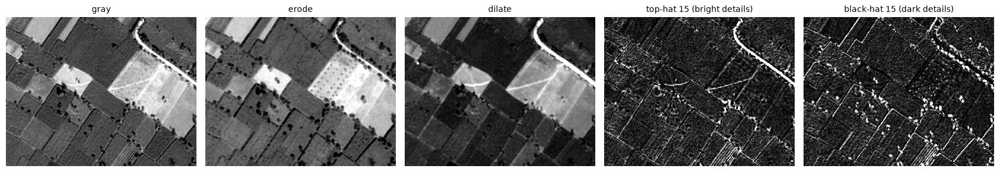

In [21]:
red_ph = photo.isel(band=0)  # red band of the photo
# erosion, dilation, top-hat and black-hat on the grey image
show([gray, ip.morphology(gray, "erode", 7, "disk"), ip.morphology(gray, "dilate", 7, "disk"),
      ip.morphology(gray, "tophat", 15, "disk"), ip.morphology(gray, "blackhat", 15, "disk")],
     ["gray", "erode", "dilate", "top-hat 15 (bright details)", "black-hat 15 (dark details)"], ncols=5, size=3.4)

## Feature detection and descriptors

### Harris corners

A corner is a point where the intensity changes in **every** direction. For a window with Gaussian weights $w$, the structure tensor is

$$M=\sum_{(i,j)}w(i,j)\begin{pmatrix}I_x^2&I_xI_y\\I_xI_y&I_y^2\end{pmatrix},$$

with eigenvalues $\lambda_1,\lambda_2$. Both small means a flat region, one large means an edge, both large means a corner. Harris avoids the eigen-decomposition with

$$R=\det M-k\,(\operatorname{tr}M)^2=\lambda_1\lambda_2-k(\lambda_1+\lambda_2)^2,\qquad k\approx0.05.$$

Peaks of $R$ at least `min_distance` apart and above `threshold_rel`$\cdot R_{max}$ are corners. Corners match images (registration), track field corners and locate man-made structures. Function: `harris_corners` returns an $(n,2)$ array of `(row, col)`.

### Histogram of Oriented Gradients (HOG)

The image is split into cells (e.g. $8\times8$ pixels). In each cell the gradient orientations $\theta$ vote into $n$ bins weighted by $|\nabla I|$. Cells are grouped into overlapping blocks (e.g. $2\times2$ cells) and the block vector $\mathbf v$ is normalized, $\mathbf v\leftarrow\mathbf v/\sqrt{\|\mathbf v\|_2^2+\epsilon^2}$. The concatenation of all block vectors is a fixed-length **shape descriptor** that is insensitive to illumination; it was the standard input to a linear SVM for object detection (vehicles, buildings) before deep networks. Function: `hog_features` (a flat vector, or with `visualize=True` also the HOG image).


Harris corners: 24
HOG descriptor length: 62604 = blocks x 2x2 cells x 9 bins


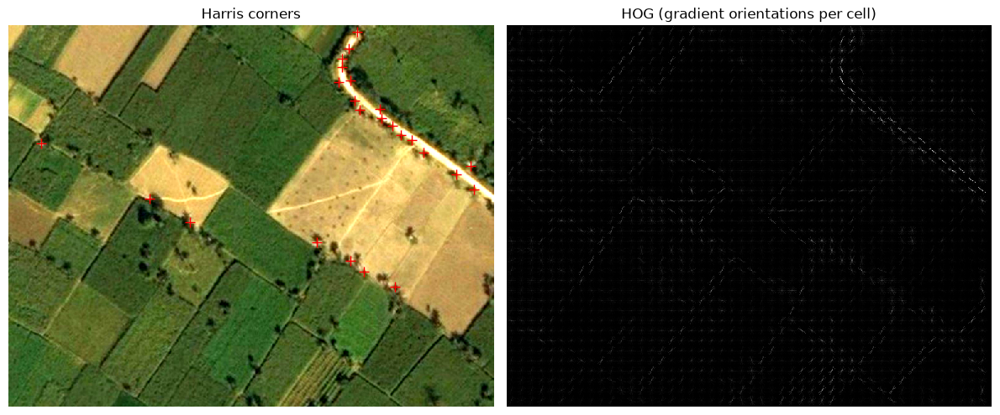

In [22]:
# Harris corners on the lightly blurred image
pts = ip.harris_corners(ip.gaussian_blur(gray, 1.0), sigma=2, min_distance=10, threshold_rel=0.02)
print("Harris corners:", len(pts))  # how many were found

# histogram-of-oriented-gradients features and their picture
hog_vec, hog_img = ip.hog_features(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)
print("HOG descriptor length:", hog_vec.shape[0], "= blocks x 2x2 cells x 9 bins")  # descriptor length

fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # two panels
# corners on the photo
axes[0].imshow(to_show(photo)); axes[0].plot(pts[:, 1], pts[:, 0], "r+", ms=8); axes[0].set_title("Harris corners"); axes[0].axis("off")
# the HOG picture
axes[1].imshow(hog_img, cmap="gray"); axes[1].set_title("HOG (gradient orientations per cell)"); axes[1].axis("off")
plt.tight_layout(); plt.show()  # arrange and draw

## A multispectral workflow with no-data

The 8-band image has large NaN areas. NaN pixels are excluded from every statistic and filter, and stay NaN in the output, so the pipeline needs no manual masking. Bands: 1 coastal, 2 blue, 3 green, 4 yellow, 5 red, 6 red edge, 7 NIR1, 8 NIR2 (index 0-7 below).

1. False-color stretch (NIR, red, green).
2. NDVI and a red-edge index $\mathrm{NDRE}=(\rho_{NIR}-\rho_{RE})/(\rho_{NIR}+\rho_{RE})$.
3. Median filter to reduce pixel noise while keeping field boundaries.
4. Otsu threshold and morphological clean-up.


NaN preserved by the filter: True
valid pixels 420000, Otsu T = 0.182, vegetation fraction 90.45%


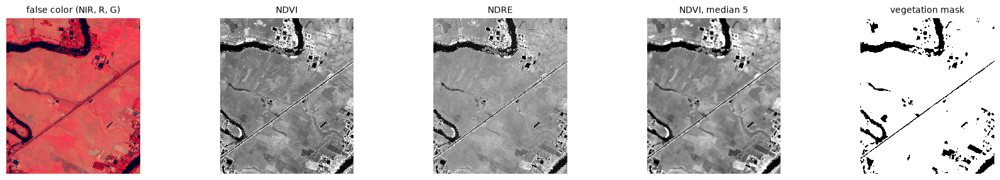

In [20]:
b = lambda i: multi.isel(band=i).astype("float64")  # one band as float
# NDVI from NIR (band 7) and red (band 5)
ndvi8 = ((b(6) - b(4)) / (b(6) + b(4))).expand_dims(band=[1]).astype("float32")
# red-edge NDVI from NIR and red edge (band 6)
ndre8 = ((b(6) - b(5)) / (b(6) + b(5))).expand_dims(band=[1]).astype("float32")
ndvi_med = ip.median_blur(ndvi8, 5)  # median filter keeps the NaN gaps
# the gaps are unchanged
print("NaN preserved by the filter:", bool(np.array_equal(np.isnan(ndvi8.values), np.isnan(ndvi_med.values))))

veg8, T = ip.threshold(ndvi_med, "otsu", return_value=True)  # Otsu threshold on the smoothed NDVI
veg8 = ip.remove_small_objects(ip.morphology(veg8, "open", 3, "disk"), min_size=40)  # open and drop small blobs
valid = ~np.isnan(ndvi8.values[0])  # pixels with data
# threshold and vegetation share
print(f"valid pixels {valid.sum()}, Otsu T = {T[0] if isinstance(T, list) else T:.3f}, vegetation fraction {veg8.values[0][valid].mean():.2%}")

# false colour, indices and the mask
show([multi.isel(band=[6, 4, 2]), ndvi8, ndre8, ndvi_med, np.where(valid, veg8.values[0], np.nan)],
     ["false color (NIR, R, G)", "NDVI", "NDRE", "NDVI, median 5", "vegetation mask"], ncols=5, size=3.5)

## From processed layers to a classifier

Every output above is a new band. Stack several, flatten with `to_vector`, and the matrix is ready for any classifier in `geolattice.rsense.classify`. Here k-means (unsupervised) clusters the photo from: Lab color, Gaussian-smoothed Lab (context), Sobel edges and a local-variance texture proxy,

$$\hat\mu_w(r,c)=\frac{1}{w^2}\sum I,\qquad \sigma^2_w=\hat\mu_w(I^2)-\hat\mu_w(I)^2 ,$$

computed with two box filters. Features are standardized, $z=(x-\bar x)/s$, so no layer dominates the Euclidean distance.


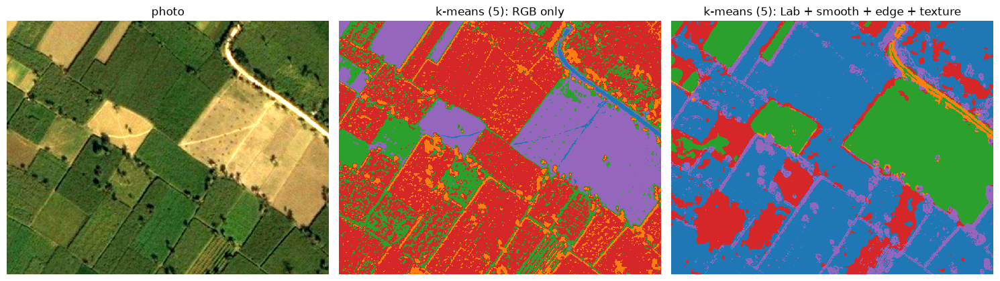

feature matrix shape for the rich stack: (472750, 8)


In [21]:
from sklearn.cluster import KMeans  # k-means clustering

L = lab.isel(band=0)  # lightness band
smooth_lab = ip.gaussian_blur(lab, 3.0)  # smoothed L*a*b*
edge = ip.edges(gray, "sobel")  # Sobel edge magnitude
mean1 = ip.mean_blur(gray, 9)  # local mean
mean2 = ip.mean_blur(gray * gray, 9)  # local mean of the squares
local_var = (mean2 - mean1 ** 2).clip(min=0)  # local variance (texture)

def stack(*layers):  # stack layers into one (feature, y, x) array
    # every layer flattened to (n, y, x) and concatenated
    return np.concatenate([np.asarray(l.values if hasattr(l, "values") else l).reshape(-1, *l.shape[-2:]) for l in layers])

rgb_feat = stack(photo.astype("float32"))  # RGB only
rich_feat = stack(lab, smooth_lab, edge, local_var)  # colour, smoothed colour, edges and texture
results = {}  # cluster maps
# the two feature sets
for name, feat in [("RGB only", rgb_feat), ("Lab + smooth + edge + texture", rich_feat)]:
    X = ip.to_vector(feat)  # pixels as rows
    X = (X - X.mean(0)) / X.std(0)  # standardise each feature
    km = KMeans(n_clusters=5, n_init=4, random_state=0).fit(X)  # five clusters
    results[name] = km.labels_.reshape(feat.shape[1:])  # cluster labels as an image

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))  # three panels
axes[0].imshow(to_show(photo)); axes[0].set_title("photo")  # the photo
for ax, (k, v) in zip(axes[1:], results.items()):  # one cluster map per feature set
    # draw it
    ax.imshow(v, cmap="tab10", vmin=0, vmax=9, interpolation="nearest"); ax.set_title(f"k-means (5): {k}")
for ax in axes: ax.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw
# size of the rich feature matrix
print("feature matrix shape for the rich stack:", ip.to_vector(rich_feat).shape)

The color-only map is speckled because neighbouring pixels of one field differ in color. Adding smoothed and texture layers makes clusters spatially coherent, which is the idea behind object-based classification (notebook 09_09_02_01) without any segmentation step.

## Summary, exercises and references

### Algorithm to function map

| Task | Function | Math |
|---|---|---|
| Read / write / info | `read_image`, `write_image`, `image_info` | affine geo-transform |
| Gray, HSV, Lab | `to_gray`, `rgb_to_hsv`, `rgb_to_lab` | weighted sum, chroma/value, $f(t)=t^{1/3}$ |
| Resample | `resize`, `rescale`, `downscale_local_mean` | nearest / bilinear / bicubic, block mean |
| Warp | `rotate`, `shift`, `flip`, `crop`, `affine_transform`, `perspective_transform` | affine (6 dof), homography (8 dof) |
| Stretch, gamma | `stretch`, `adjust_gamma`, `adjust_brightness_contrast` | percentile scaling, $I^\gamma$, $\alpha I+\beta$ |
| Histogram | `histogram`, `equalize_hist`, `equalize_adapthist`, `match_histograms` | $F(I)$, clipped local CDF, $F_R^{-1}F_A$ |
| Threshold | `threshold` | Otsu $\max\sigma_B^2$, Li, triangle, Yen, local mean |
| Filters | `convolve`, `mean_blur`, `gaussian_blur`, `median_blur`, `bilateral_denoise`, `tv_denoise` | $\sum K\,I$, $G_\sigma$, median, bilateral, TV |
| Sharpen / noise | `sharpen`, `unsharp_mask`, `add_noise` | $I-\nabla^2I$, $I+a(I-G_\sigma*I)$, PSNR |
| Edges | `edges`, `sobel_h`, `sobel_v` | $\|\nabla I\|$, Laplacian, Canny |
| Morphology | `morphology`, `remove_small_objects` | min / max over $B$, open, close, top-hat |
| Features | `harris_corners`, `hog_features`, `to_vector` | $\det M-k\,\mathrm{tr}^2M$, HOG, $(HW)\times B$ |

### Practical rules

* Stretch for display, but classify on the physical values (reflectance), not on stretched ones.
* Resample class maps with nearest neighbour (`order=0`) and continuous data with bilinear or bicubic.
* Smooth **before** edge detection; match histograms **before** comparing dates.
* Do not use morphology or median filters to fix a classification map that a better feature would fix.

### Exercises

1. Compare `resize` with `anti_aliasing=False` and `True` when shrinking the photo by 8. Where do the differences appear, and why?
2. Implement histogram equalization with `np.cumsum` and compare with `equalize_hist`.
3. Find the `block_size` of the local threshold that best separates the track from the fields in the photo.
4. Estimate which `size` of median filter maximizes PSNR for 5 % salt-and-pepper noise.
5. Replace the Otsu threshold in section 11 by Li and triangle. How does the vegetation fraction change?
6. Add the Harris corner count per 100 × 100 block as a feature in section 12 and see which fields it separates.

### References

- Canny, J. (1986). A computational approach to edge detection. *IEEE TPAMI*, 8(6), 679-698.
- Dalal, N., Triggs, B. (2005). Histograms of oriented gradients for human detection. *CVPR*.
- Chambolle, A. (2004). An algorithm for total variation minimization and applications. *J. Math. Imaging Vis.*, 20, 89-97.
- Harris, C., Stephens, M. (1988). A combined corner and edge detector. *Alvey Vision Conference*.
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Trans. SMC*, 9(1), 62-66.
- Pizer, S. M. et al. (1987). Adaptive histogram equalization and its variations. *Computer Vision, Graphics, and Image Processing*, 39, 355-368.
- Tomasi, C., Manduchi, R. (1998). Bilateral filtering for gray and color images. *ICCV*.
- van der Walt, S. et al. (2014). scikit-image: image processing in Python. *PeerJ*, 2, e453.
- Bradski, G. (2000). The OpenCV library. *Dr. Dobb's Journal of Software Tools*.
